# 02. Viewing Downloaded Manuscript Images

This notebook lets you browse manuscript facsimile images downloaded through the project's IIIF pipeline.

Images are organized in structured folders under `images/`, linked directly to the catalogue metadata in `data/csv/MANUSCRIPTS_IMAGES_INDEX.csv` and `data/csv/PAGE_LEVEL_METADATA.csv`.

## 1. Index of Downloaded Manuscripts

Let's load the central index to see all downloaded manuscripts, their shelfmarks, holding libraries, and page counts.

In [1]:
from pathlib import Path
import json
import pandas as pd
from PIL import Image
from IPython.display import display

# Robust path resolution (works from notebooks/ or project root)
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "images").exists() else Path.cwd().parent
IMAGES_DIR = PROJECT_ROOT / "images"
CSV_DIR = PROJECT_ROOT / "data" / "csv"

# Load downloaded manuscripts index
index_file = CSV_DIR / "MANUSCRIPTS_IMAGES_INDEX.csv"
if index_file.exists():
    df_index = pd.read_csv(index_file)
    display(df_index[["library_code", "shelfmark", "title", "downloaded_pages", "folder_path"]])
else:
    print("Index file not found yet. Listing directories in images/:")
    for f in sorted(IMAGES_DIR.iterdir()):
        if f.is_dir() and not f.name.startswith("."):
            print(" -", f.name)

,library_code,shelfmark,title,downloaded_pages,folder_path
0,BnF,Ms. hebr. 1105,איל טראטאדו דילא איספירא.,94,images/990001314740205171_BnF_Ms._hebr._1105
1,BnF,Ms. hebr. 1005,אישפירא.,144,images/990001309470205171_BnF_Ms._hebr._1005
2,NLI,Ms. Heb. 6694=28,ספר הגלגל.,20,images/990000463750205171_NLI_Ms._Heb._6694_28
3,HUC,Ms. 900,ספר הגלגל.,0,images/990001271930205171_HUC_Ms._900
4,BSB,Cod.hebr. 394,ספר הגלגל.,335,images/990001283830205171_BSB_Cod.hebr._394
5,BnF,Ms. hebr. 1092,ספר הגלגל.,371,images/990001314250205171_BnF_Ms._hebr._1092
6,University,Ms. Oct. 62,ספר הגלגל.,106,images/990001379080205171_University_Ms._Oct._62
7,RSL,Ms. Guenzburg 1067,ספר הגלגל.,12,images/990001467840205171_RSL_Ms._Guenzburg_1067
8,EtsHaim,47 D 20,ספר הגלגל.,0,images/990001490910205171_EtsHaim_47_D_20
9,The_Nation,Ms. EVR I 355,ספר הגלגל.,0,images/990001513930205171_The_Nation_Ms._EVR_I...


## 2. Select and Inspect a Manuscript

Choose a manuscript by setting `selected_folder` below (copy from the index table above, or browse any folder in `images/`).

You can control how many pages to display using `max_pages` (to avoid scrolling through hundreds of pages at once).

=== Manuscript Metadata ===
Title:     ספר הגלגל.
Library:   The National Library of Israel (NLI)
Shelfmark: Ms. Heb. 6694=28
Script:    אשכנזית
Pages:     20 downloaded

Displaying 5 of 20 pages from: 990000463750205171_NLI_Ms._Heb._6694_28

--- Page 1: 0001.jpg | Dimensions: 1200x948 px | Size: 72.7 KB ---


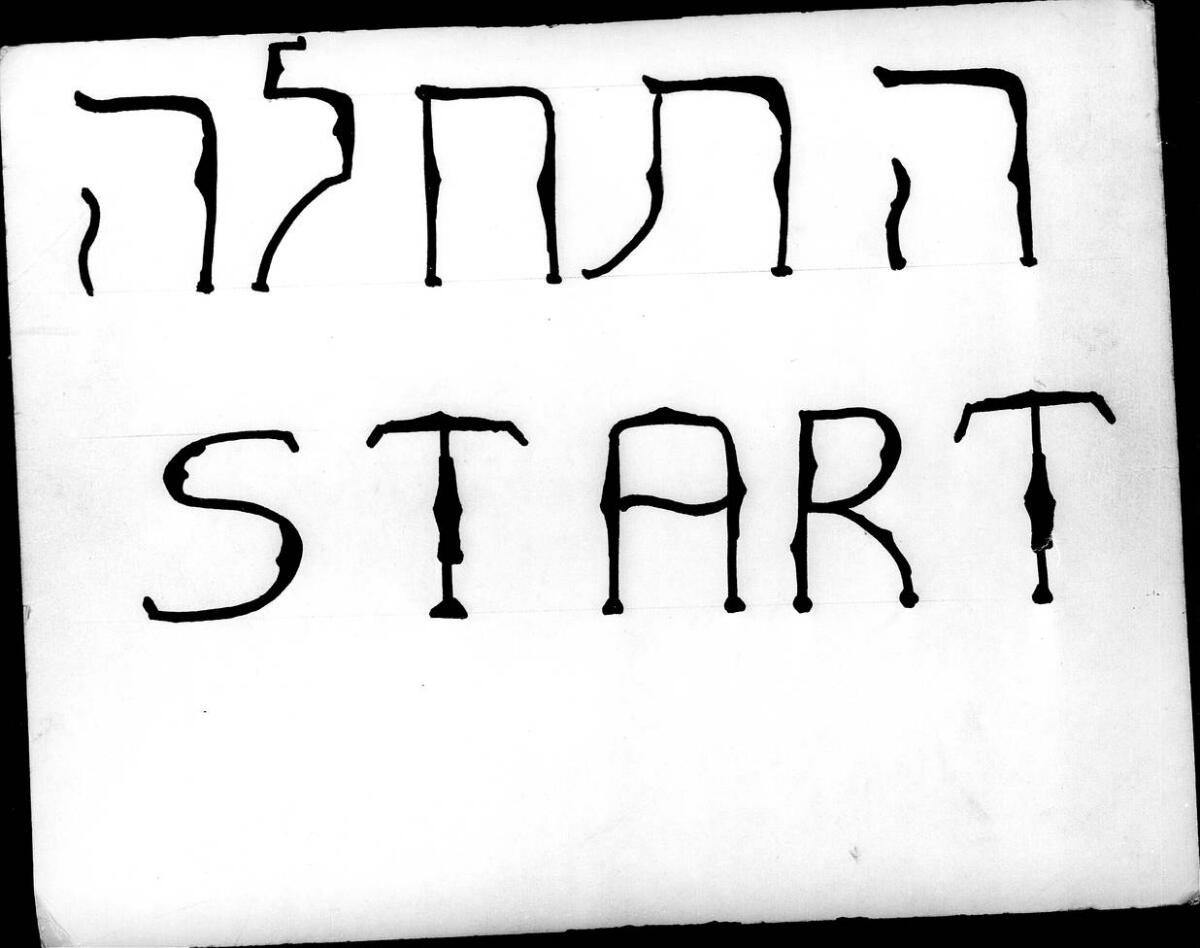

--- Page 2: 0002.jpg | Dimensions: 1200x1250 px | Size: 142.6 KB ---


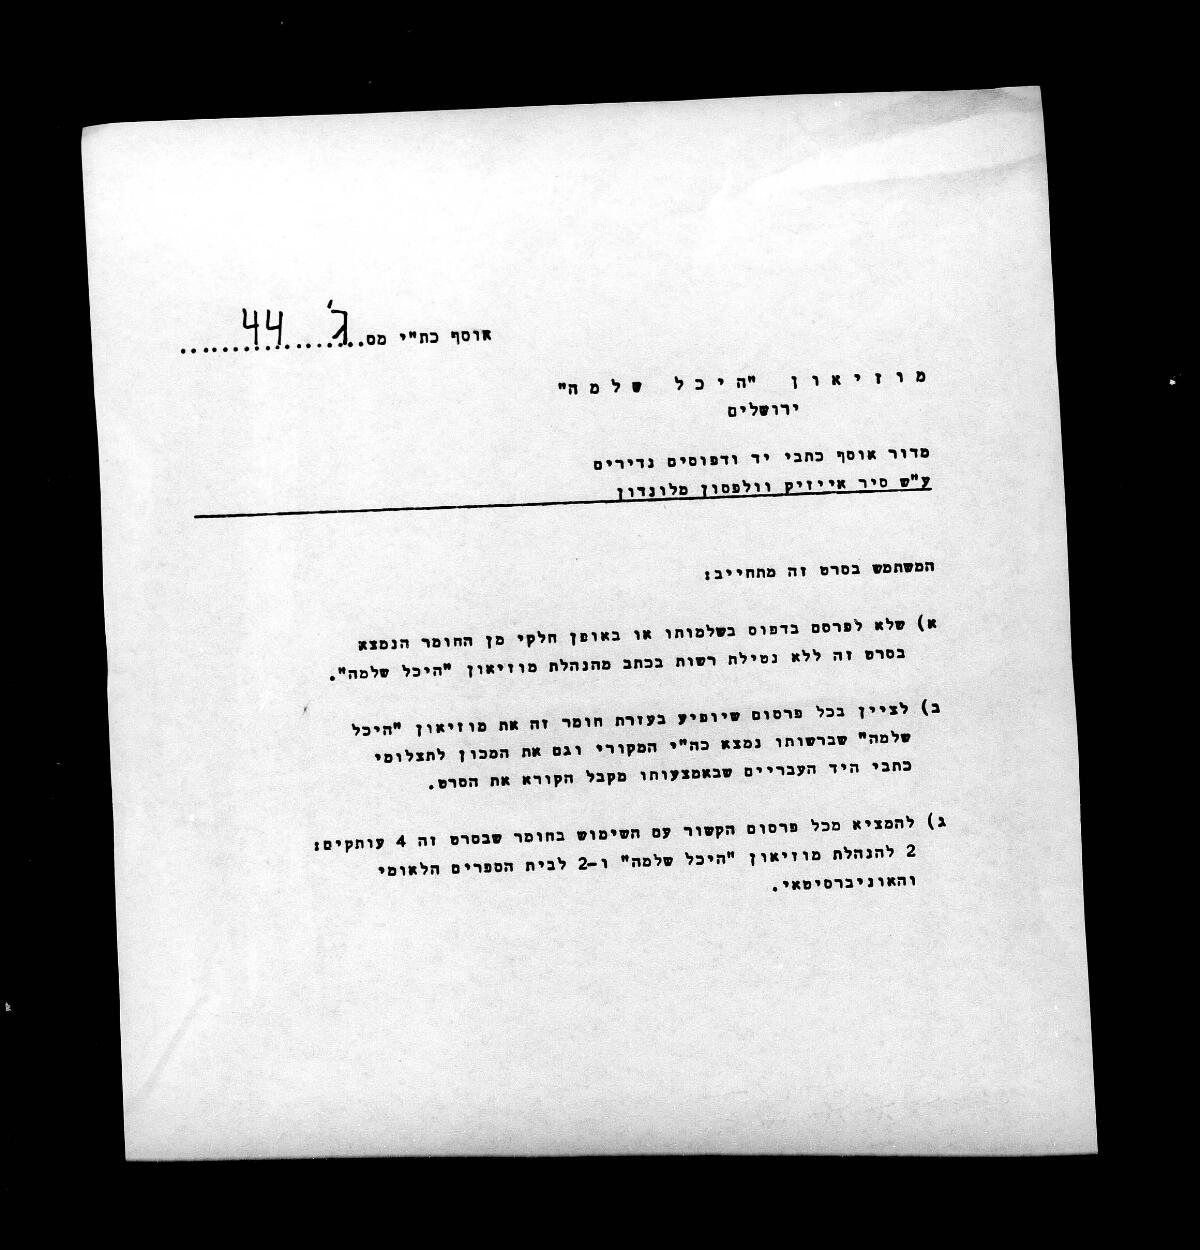

--- Page 3: 0003.jpg | Dimensions: 1200x904 px | Size: 96.5 KB ---


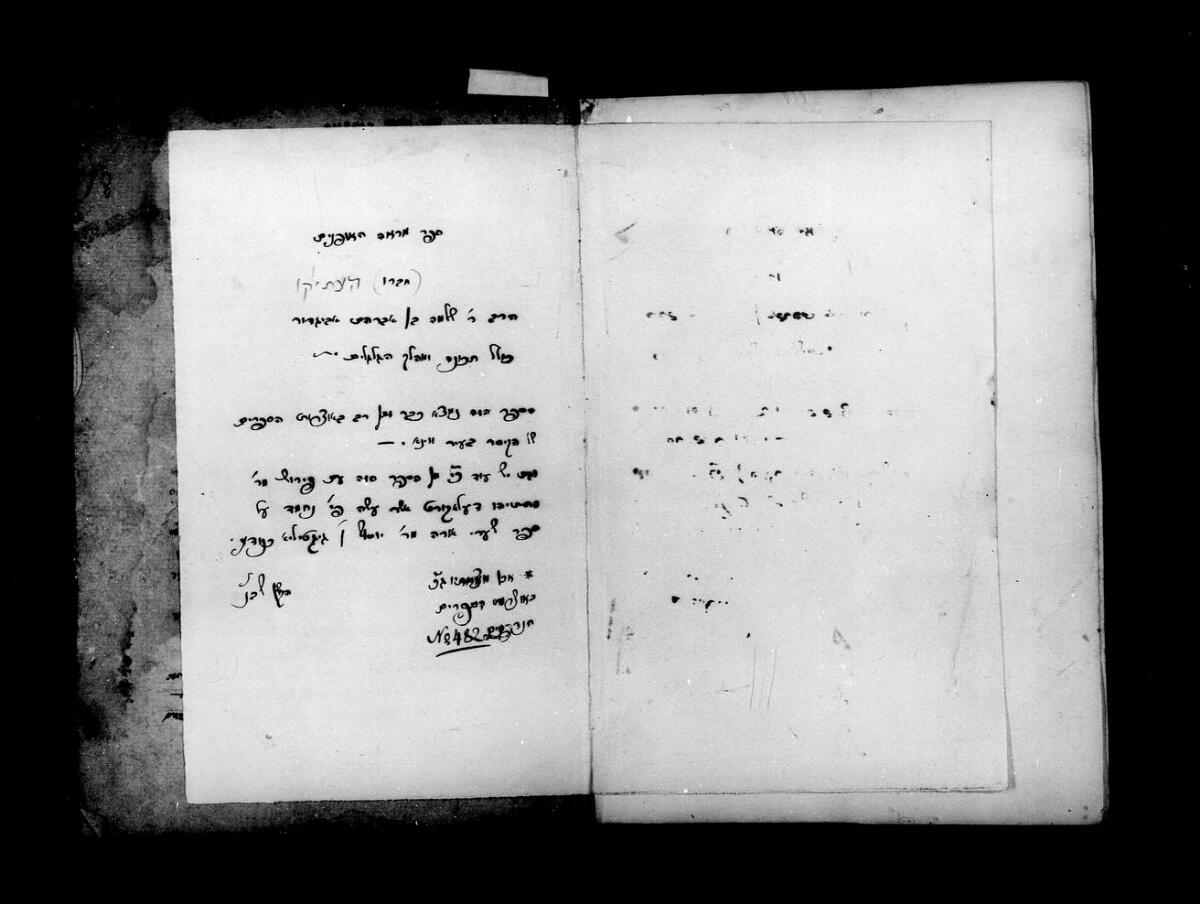

--- Page 4: 0004.jpg | Dimensions: 1200x907 px | Size: 104.7 KB ---


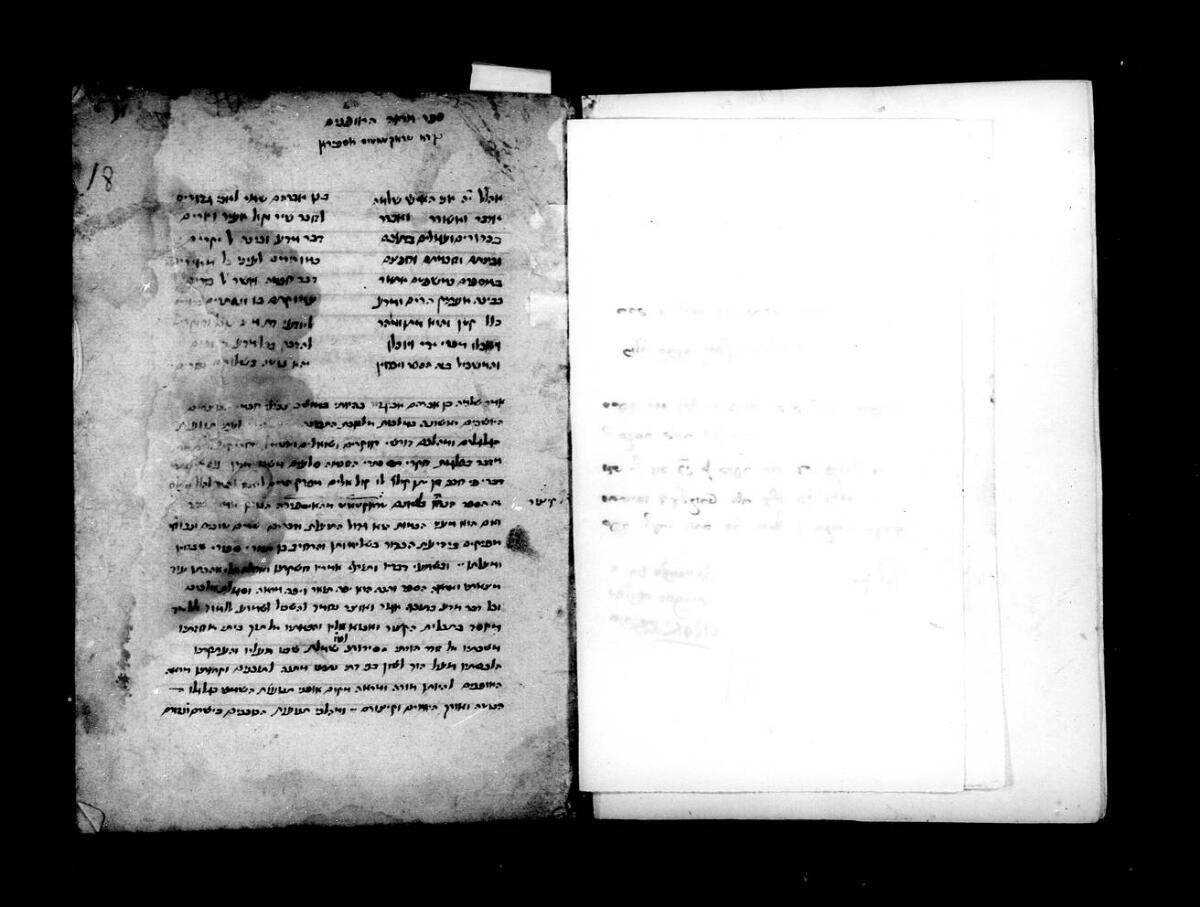

--- Page 5: 0005.jpg | Dimensions: 1200x918 px | Size: 152.6 KB ---


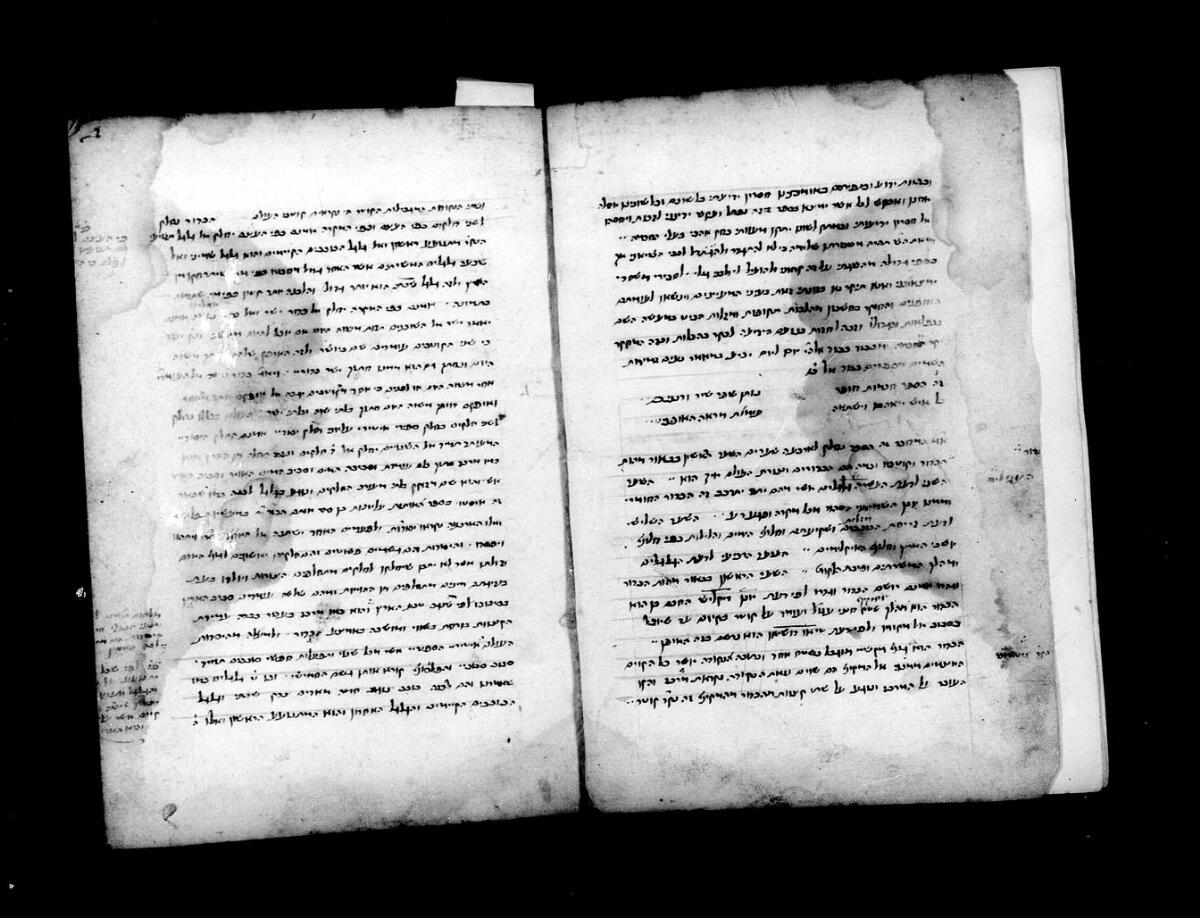

In [2]:
# --- Configuration: Choose manuscript folder and page display limit ---
selected_folder = "990000463750205171_NLI_Ms._Heb._6694_28"  # e.g. "990001314740205171_BnF_Ms._hebr._1105", "JTS_9121", etc.
max_pages_to_show = 5  # Set to None to show all pages in the folder

target_dir = IMAGES_DIR / selected_folder

if not target_dir.exists():
    print(f"Directory not found: {target_dir}")
else:
    # 1. Display metadata if metadata.json exists
    meta_path = target_dir / "metadata.json"
    if meta_path.exists():
        with open(meta_path, "r", encoding="utf-8") as f:
            meta = json.load(f)
        print("=== Manuscript Metadata ===")
        print(f"Title:     {meta.get('title')}")
        print(f"Library:   {meta.get('holding_library')} ({meta.get('library_code')})")
        print(f"Shelfmark: {meta.get('shelfmark')}")
        print(f"Script:    {meta.get('script') or 'Not recorded'}")
        if meta.get("colophon"):
            print(f"Colophon:  {meta.get('colophon')[:120]}...")
        print(f"Pages:     {meta.get('downloaded_pages')} downloaded\n")
        
    # 2. Display pages
    image_paths = sorted(target_dir.glob("*.jpg"))
    display_paths = image_paths[:max_pages_to_show] if max_pages_to_show else image_paths
    
    print(f"Displaying {len(display_paths)} of {len(image_paths)} pages from: {selected_folder}\n")
    
    for idx, img_path in enumerate(display_paths, 1):
        with Image.open(img_path) as im:
            w, h = im.size
            file_kb = img_path.stat().st_size / 1024
            print(f"--- Page {idx}: {img_path.name} | Dimensions: {w}x{h} px | Size: {file_kb:.1f} KB ---")
            display(im.copy())